### Import dan setup path

In [2]:
import os
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

current = Path(os.getcwd())
if (current / "data").exists():
    BASE_DIR = current
elif (current.parent / "data").exists():
    BASE_DIR = current.parent
else:
    raise FileNotFoundError("Folder 'data' tidak ditemukan, cek lokasi notebook")

CLEAN_DIR = BASE_DIR / "data" / "clean"
ANALYTICS_DIR = BASE_DIR / "data" / "analytics"
ANALYTICS_DIR.mkdir(parents=True, exist_ok=True)

### Baca semua input

In [3]:
df_aspek = pd.read_csv(CLEAN_DIR / "ringkasan_aspek_mahasiswa.csv")
df_item = pd.read_csv(CLEAN_DIR / "ringkasan_item_mahasiswa.csv")
df_kategori = pd.read_csv(CLEAN_DIR / "kategori_mahasiswa_clean.csv")
df_frek = pd.read_csv(ANALYTICS_DIR / "frekuensi_aspek_mahasiswa.csv")

total_responden_kategori = df_kategori["response_id"].nunique()
print("Responden yang mengisi pertanyaan prioritas:", total_responden_kategori)

print("\nPilihan yang muncul di form:")
print(df_kategori["pilihan"].value_counts())

Responden yang mengisi pertanyaan prioritas: 418

Pilihan yang muncul di form:
pilihan
Parkir                                 336
Internet/Wi-Fi dan Sistem Informasi    316
Toilet                                  92
Laboratorium                            90
Administrasi Akademik                   69
Ruang Kuliah                            63
Layanan Kemahasiswaan                   60
Lingkungan Kampus                       40
Perpustakaan                            26
Administrasi Umum                       21
Layanan Klinik                          18
Administrasi Keuangan                   12
Name: count, dtype: int64


### Petakan pilihan prioritas ke aspek

In [4]:
# Sesuaikan kata-kata ini dengan isi 'pilihan' di output Cell 2
KATA_PILIHAN = {
    "Administrasi Akademik": ["akademik"],
    "Kemahasiswaan": ["kemahasiswaan", "beasiswa"],
    "Administrasi Keuangan": ["keuangan"],
    "Administrasi Umum": ["administrasi umum"],
    "Ruang Kuliah": ["ruang kuliah", "kelas"],
    "Laboratorium": ["laboratorium", "lab"],
    "Perpustakaan": ["perpustakaan"],
    "TIK dan Sistem Informasi kampus": ["tik", "sistem informasi", "wifi", "wi-fi", "internet"],
    "Toilet kampus": ["toilet"],
    "Parkir kampus": ["parkir"],
    "Lingkungan Kampus": ["lingkungan"],
    "Klinik Kampus": ["klinik"]
}

def cocokkan_pilihan(pilihan):
    teks = str(pilihan).lower()
    for aspek, daftar_kata in KATA_PILIHAN.items():
        for kata in daftar_kata:
            if re.search(r"\b" + re.escape(kata) + r"\b", teks):
                return aspek
    return "Tidak terpetakan"

df_kategori["aspek"] = df_kategori["pilihan"].apply(cocokkan_pilihan)

print("Pilihan yang belum terpetakan (perbaiki KATA_PILIHAN kalau ada):")
print(df_kategori[df_kategori["aspek"] == "Tidak terpetakan"]["pilihan"].value_counts())

Pilihan yang belum terpetakan (perbaiki KATA_PILIHAN kalau ada):
Series([], Name: count, dtype: int64)


### Hitung seberapa asing aspek dipilih sebagai prioritas

In [5]:
df_pilih = df_kategori[df_kategori["aspek"] != "Tidak terpetakan"]

# satu responden dihitung sekali per aspek
df_pilih = df_pilih.drop_duplicates(subset=["response_id", "aspek"])

hitung_pilih = df_pilih.groupby("aspek")["response_id"].nunique().reset_index()
hitung_pilih.columns = ["aspek", "jumlah_dipilih"]
hitung_pilih["persen_dipilih"] = (hitung_pilih["jumlah_dipilih"] / total_responden_kategori * 100).round(1)

hitung_pilih.sort_values("jumlah_dipilih", ascending=False)

,aspek,jumlah_dipilih,persen_dipilih
7,Parkir kampus,336,80.4
10,TIK dan Sistem Informasi kampus,316,75.6
11,Toilet kampus,92,22.0
5,Laboratorium,90,21.5
0,Administrasi Akademik,69,16.5
9,Ruang Kuliah,63,15.1
3,Kemahasiswaan,60,14.4
6,Lingkungan Kampus,40,9.6
8,Perpustakaan,26,6.2
2,Administrasi Umum,21,5.0


### Gabungkan tiga sumber data

In [6]:
df_prioritas = df_aspek[["aspek", "rata_rata"]].copy()
df_prioritas = df_prioritas.rename(columns={"rata_rata": "skor_kepuasan"})

df_prioritas = df_prioritas.merge(hitung_pilih, on="aspek", how="left")
df_prioritas = df_prioritas.merge(df_frek[["aspek", "frekuensi"]], on="aspek", how="left")
df_prioritas = df_prioritas.rename(columns={"frekuensi": "frekuensi_komentar"})
df_prioritas = df_prioritas.fillna(0)

df_prioritas

,aspek,skor_kepuasan,jumlah_dipilih,persen_dipilih,frekuensi_komentar
0,Parkir kampus,2.51,336,80.4,206
1,TIK dan Sistem Informasi kampus,2.72,316,75.6,105
2,Toilet kampus,3.05,92,22.0,32
3,Administrasi Akademik,3.12,69,16.5,25
4,Kemahasiswaan,3.14,60,14.4,99
5,Administrasi Umum,3.18,21,5.0,5
6,Laboratorium,3.19,90,21.5,45
7,Ruang Kuliah,3.20,63,15.1,42
8,Administrasi Keuangan,3.24,12,2.9,5
9,Lingkungan Kampus,3.27,40,9.6,27


### Hitung skor prioritas dan ranking

In [7]:
# Bobot adalah usulan awal, perlu disepakati tim (jumlah harus 1)
BOBOT_KETIDAKPUASAN = 1 / 3   # skor kepuasan rendah -> prioritas tinggi
BOBOT_PILIHAN = 1 / 3         # sering dipilih responden sebagai prioritas
BOBOT_KOMENTAR = 1 / 3        # sering disebut di komentar

def minmax(seri):
    selisih = seri.max() - seri.min()
    if selisih == 0:
        return seri * 0
    return (seri - seri.min()) / selisih

df_prioritas["norm_ketidakpuasan"] = 1 - minmax(df_prioritas["skor_kepuasan"])
df_prioritas["norm_pilihan"] = minmax(df_prioritas["persen_dipilih"])
df_prioritas["norm_komentar"] = minmax(df_prioritas["frekuensi_komentar"])

df_prioritas["skor_prioritas"] = (
    BOBOT_KETIDAKPUASAN * df_prioritas["norm_ketidakpuasan"]
    + BOBOT_PILIHAN * df_prioritas["norm_pilihan"]
    + BOBOT_KOMENTAR * df_prioritas["norm_komentar"]
).round(3)

df_prioritas = df_prioritas.sort_values("skor_prioritas", ascending=False).reset_index(drop=True)
df_prioritas["ranking"] = df_prioritas.index + 1

def tentukan_level(ranking, jumlah):
    if ranking <= jumlah / 3:
        return "Tinggi"
    elif ranking <= 2 * jumlah / 3:
        return "Sedang"
    else:
        return "Rendah"

jumlah_aspek = len(df_prioritas)
df_prioritas["level_prioritas"] = df_prioritas["ranking"].apply(lambda r: tentukan_level(r, jumlah_aspek))

df_prioritas[["ranking", "aspek", "skor_kepuasan", "persen_dipilih",
              "frekuensi_komentar", "skor_prioritas", "level_prioritas"]]

,ranking,aspek,skor_kepuasan,persen_dipilih,frekuensi_komentar,skor_prioritas,level_prioritas
0,1,Parkir kampus,2.51,80.4,206,1.000,Tinggi
1,2,TIK dan Sistem Informasi kampus,2.72,75.6,105,0.729,Tinggi
2,3,Kemahasiswaan,3.14,14.4,99,0.289,Tinggi
3,4,Toilet kampus,3.05,22.0,32,0.246,Tinggi
4,5,Laboratorium,3.19,21.5,45,0.210,Sedang
5,6,Administrasi Akademik,3.12,16.5,25,0.183,Sedang
6,7,Ruang Kuliah,3.20,15.1,42,0.173,Sedang
7,8,Lingkungan Kampus,3.27,9.6,27,0.097,Sedang
8,9,Administrasi Umum,3.18,5.0,5,0.076,Rendah
9,10,Perpustakaan,3.30,6.2,13,0.047,Rendah


### Grafik ranking prioritas

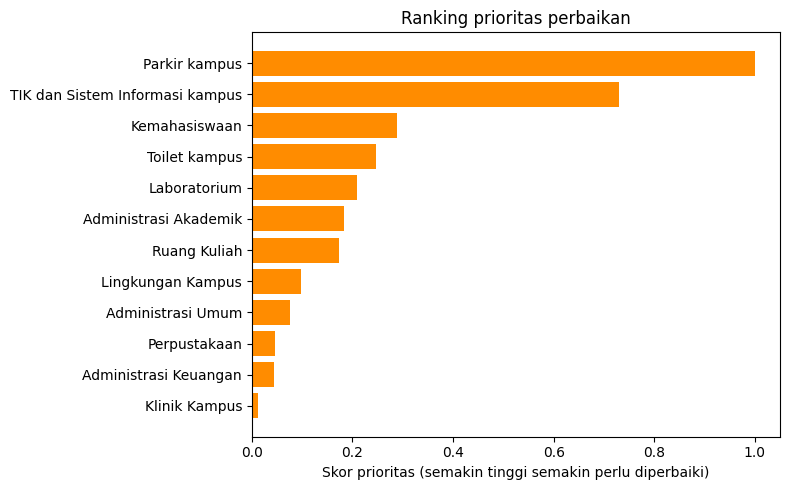

In [8]:
plt.figure(figsize=(8, 5))
plt.barh(df_prioritas["aspek"][::-1], df_prioritas["skor_prioritas"][::-1], color="darkorange")
plt.xlabel("Skor prioritas (semakin tinggi semakin perlu diperbaiki)")
plt.title("Ranking prioritas perbaikan")
plt.tight_layout()
plt.show()

### Kuadran prioritas

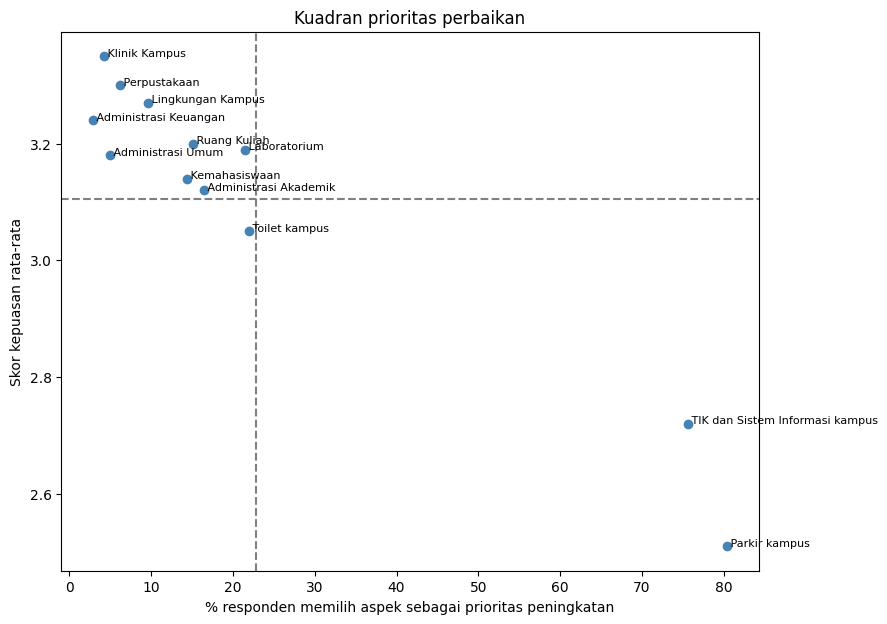

,aspek,kuadran
0,Parkir kampus,Prioritas Utama
1,TIK dan Sistem Informasi kampus,Prioritas Utama
2,Kemahasiswaan,Sudah Cukup
3,Toilet kampus,Prioritas Rendah
4,Laboratorium,Sudah Cukup
5,Administrasi Akademik,Sudah Cukup
6,Ruang Kuliah,Sudah Cukup
7,Lingkungan Kampus,Sudah Cukup
8,Administrasi Umum,Sudah Cukup
9,Perpustakaan,Sudah Cukup


In [9]:
rata_x = df_prioritas["persen_dipilih"].mean()
rata_y = df_prioritas["skor_kepuasan"].mean()

def tentukan_kuadran(x, y):
    if x >= rata_x and y < rata_y:
        return "Prioritas Utama"
    elif x >= rata_x and y >= rata_y:
        return "Pertahankan"
    elif x < rata_x and y < rata_y:
        return "Prioritas Rendah"
    else:
        return "Sudah Cukup"

df_prioritas["kuadran"] = df_prioritas.apply(
    lambda baris: tentukan_kuadran(baris["persen_dipilih"], baris["skor_kepuasan"]), axis=1
)

plt.figure(figsize=(9, 7))
plt.scatter(df_prioritas["persen_dipilih"], df_prioritas["skor_kepuasan"], color="steelblue")
for _, baris in df_prioritas.iterrows():
    plt.text(baris["persen_dipilih"], baris["skor_kepuasan"], " " + baris["aspek"], fontsize=8)

plt.axvline(rata_x, color="gray", linestyle="--")
plt.axhline(rata_y, color="gray", linestyle="--")
plt.xlabel("% responden memilih aspek sebagai prioritas peningkatan")
plt.ylabel("Skor kepuasan rata-rata")
plt.title("Kuadran prioritas perbaikan")
plt.show()

df_prioritas[["aspek", "kuadran"]]

### Drill-drown: pertanyaan terendah pada aspek prioritas teratas

In [10]:
top_aspek = df_prioritas.head(3)["aspek"].tolist()

for aspek in top_aspek:
    print("\n==", aspek, "==")
    sub = df_item[df_item["aspek"] == aspek].sort_values("rata_rata").head(3)
    print(sub[["item_kode", "pertanyaan", "rata_rata", "n_responden"]].to_string(index=False))


== Parkir kampus ==
item_kode                                                pertanyaan  rata_rata  n_responden
  ITEM_53   Tempat parkir cukup untuk menampung kendaraan mahasiswa       2.18          418
  ITEM_54                   Area parkir tertata dan mudah digunakan       2.40          418
  ITEM_55 Kendaraan cukup aman ketika diparkir di lingkungan kampus       2.95          418

== TIK dan Sistem Informasi kampus ==
item_kode                                                                         pertanyaan  rata_rata  n_responden
  ITEM_47              Internet/Wi-Fi kampus mudah diakses dan memiliki koneksi yang memadai       2.53          418
  ITEM_49             Ketika terjadi kendala TIK, bantuan atau penanganannya mudah diperoleh       2.79          418
  ITEM_48 Sistem informasi/aplikasi kampus mudah digunakan dan dapat diakses saat dibutuhkan       2.84          418

== Kemahasiswaan ==
item_kode                                                                      pert

### Simpan hasil -> /data/analytics

In [11]:
df_prioritas.to_csv(ANALYTICS_DIR / "prioritas_aspek_mahasiswa.csv", index=False)
print("Tersimpan:", ANALYTICS_DIR / "prioritas_aspek_mahasiswa.csv")

Tersimpan: c:\KULIAH\SEM 5\Project Analitika Data\data\analytics\prioritas_aspek_mahasiswa.csv
